# A learned lander paid for each landing

A landing that ends at rest on the pad pays 36. Fuel costs one per unit and the tank initially holds 24 units. Before first leg contact, the reserve falls by the fuel drawn on the current frame. After contact the remaining fuel still limits thrust and fuel use still costs money. A flight fails when the lander is lost or its fuel draw exceeds the tank before contact. Loss, including a crash or exit from the frame, crosses a second budget. A failed flight earns no landing revenue.

Let $H=1000$, $\beta=0.999$, $u_t$ be landing revenue less fuel expense on frame $t$, and $\tau$ be the first budget crossing. The expected stopped utility is $U_H(\pi)=\mathbb E_\pi[\sum_{0\le t<H,\ t<\tau}\beta^t u_t]$. With policy class $\Pi$ and deployment tolerance $\alpha$, the utility and reliability specification is

$$
\begin{aligned}
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad & U_H(\pi)\\
\text{subject to}\quad & p_{H-1}(\pi)=\Pr_\pi(\tau\le H-1)\le\alpha .
\end{aligned}
$$

The manuscript trains at fixed failure prices, using full utility before failure. Write $m$ for the failure price per remaining frame. The paid-landings charge $k$ is the penalty for a failure at frame 100 divided by the revenue 36. The probability above and the discounted risk $q_{\beta,H}$ in the objective give different weight to failure times.

$$
\begin{aligned}
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad &
V_m^{(H)}(\pi)=U_H(\pi)-\frac{m}{1-\beta}q_{\beta,H}(\pi),\\
& q_{\beta,H}(\pi)=\mathbb E_\pi[\beta^\tau(1-\beta^{H-\tau})\mathbf 1_{\lbrace\tau<H\rbrace}],\\
& m=\frac{36k(1-\beta)}{1-\beta^{H-100}} .
\end{aligned}
$$

[Manuscript studies and figure sources](README.md) · [Fixed-horizon evaluation](../../docs/practitioner-guide.md#step-8-validate-the-policy-you-deploy)

In [1]:
from pathlib import Path
import json

from IPython.display import Image, display
import numpy as np

from barrierpg import BudgetWrapper, Requirement, evaluate, sb3_policy
from barrierpg.callbacks import BudgetMonitor
from barrierpg.problems.landing import Landing, LandingSimulator, ProgressAid, LOSS
from barrierpg.spec import failure_charge
from barrierpg.validation import validate_direct

landing = Landing()
spec = landing.spec()
stage = landing.stage(charge=1.0)


def flight_cost(obs, action, next_obs, utility, info):
    return [info["tank_draw"], LOSS if info["lost"] else 0.0]


def make_env(stage, aid=False):
    solver_env = BudgetWrapper(LandingSimulator(landing), flight_cost, spec, stage, observe="none")
    return ProgressAid(solver_env, spec.beta, landing.aid_scale) if aid else solver_env


assert np.isclose(failure_charge(stage.m, spec.beta, 100, spec.horizon), landing.revenue)
env = make_env(stage)
try:
    env.reset(seed=1)
    for _ in range(spec.horizon):
        _, reward, terminated, truncated, info = env.step(np.ones(2, dtype=np.float32))
        if terminated or truncated:
            break
    assert info["failure"]
    assert np.isclose(reward, -failure_charge(stage.m, spec.beta, info["t"], spec.horizon))
finally:
    env.close()
print(f"Full-thrust test: the wrapper charged {abs(reward):.2f} at failure frame {info['t']}.")

Full-thrust test: the wrapper charged 36.68 at failure frame 72.


The simulator already observes the fuel fraction. The wrapper adds the two crossing conditions and the remaining-stream failure charge. In training we augment the reward with a discounted potential difference for progress toward the pad. With terminal potential zero, its discounted sum depends only on the initial observation. Evaluation uses the original utility.

## Compare the manuscript policies

The displayed campaign starts each arm from its same-seed unpriced controller, trained for 30 million interactions. Each arm then trains for 50 million interactions at a constant learning rate, followed by 10 million with decay to zero. There are ten seeds per charge and 2,000 evaluation episodes per fitted policy. Pre-touchdown fuel uses 500 further episodes per policy.

In the first figure, the individual flight panel uses 32 flights per charge from the seed selected by median combined failure risk. The descent panel uses 32 flights per seed for each charge. The second figure shows all training seeds, with medians connected across charges.

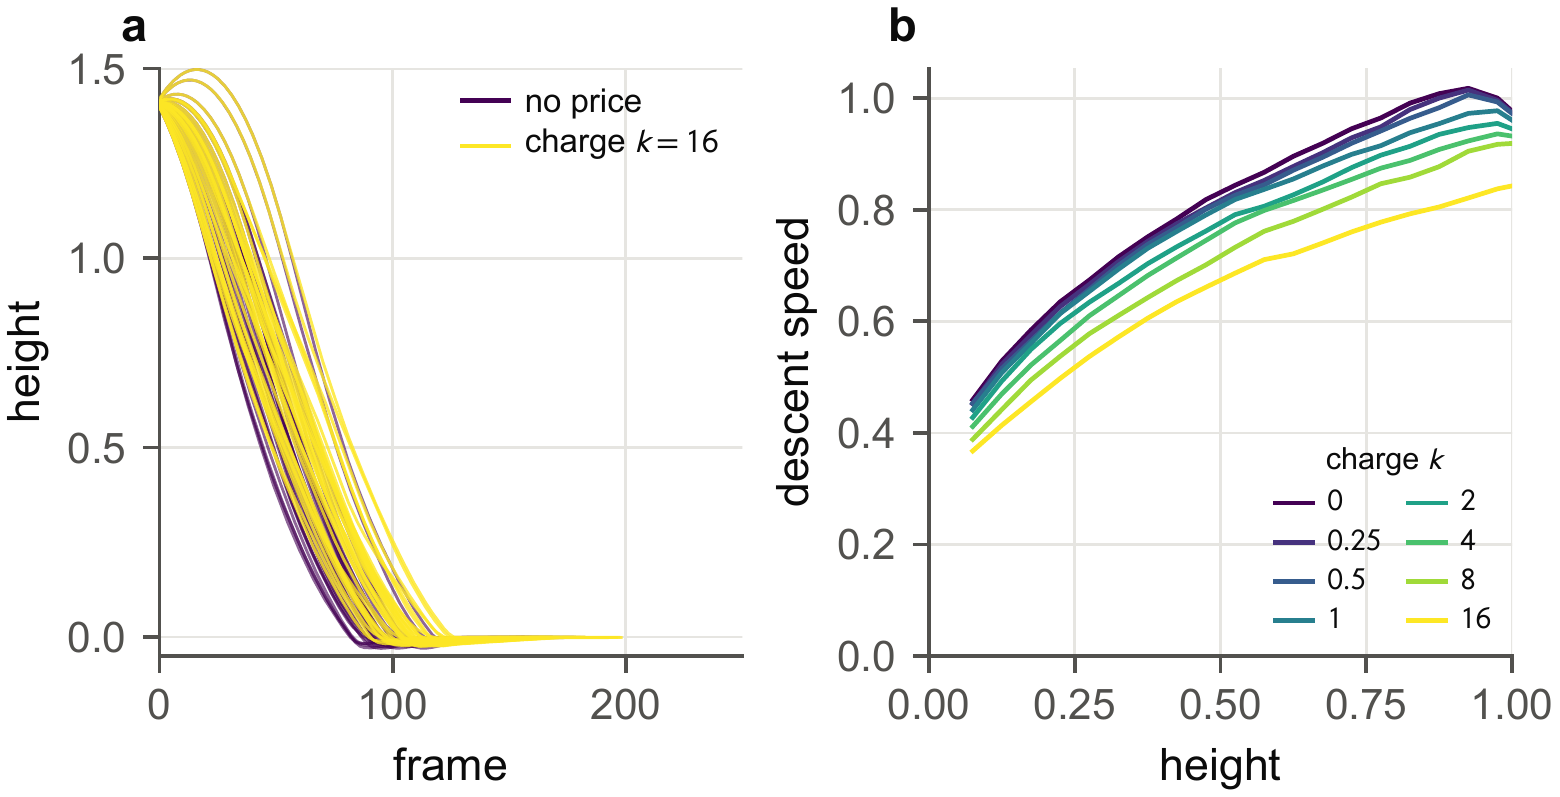

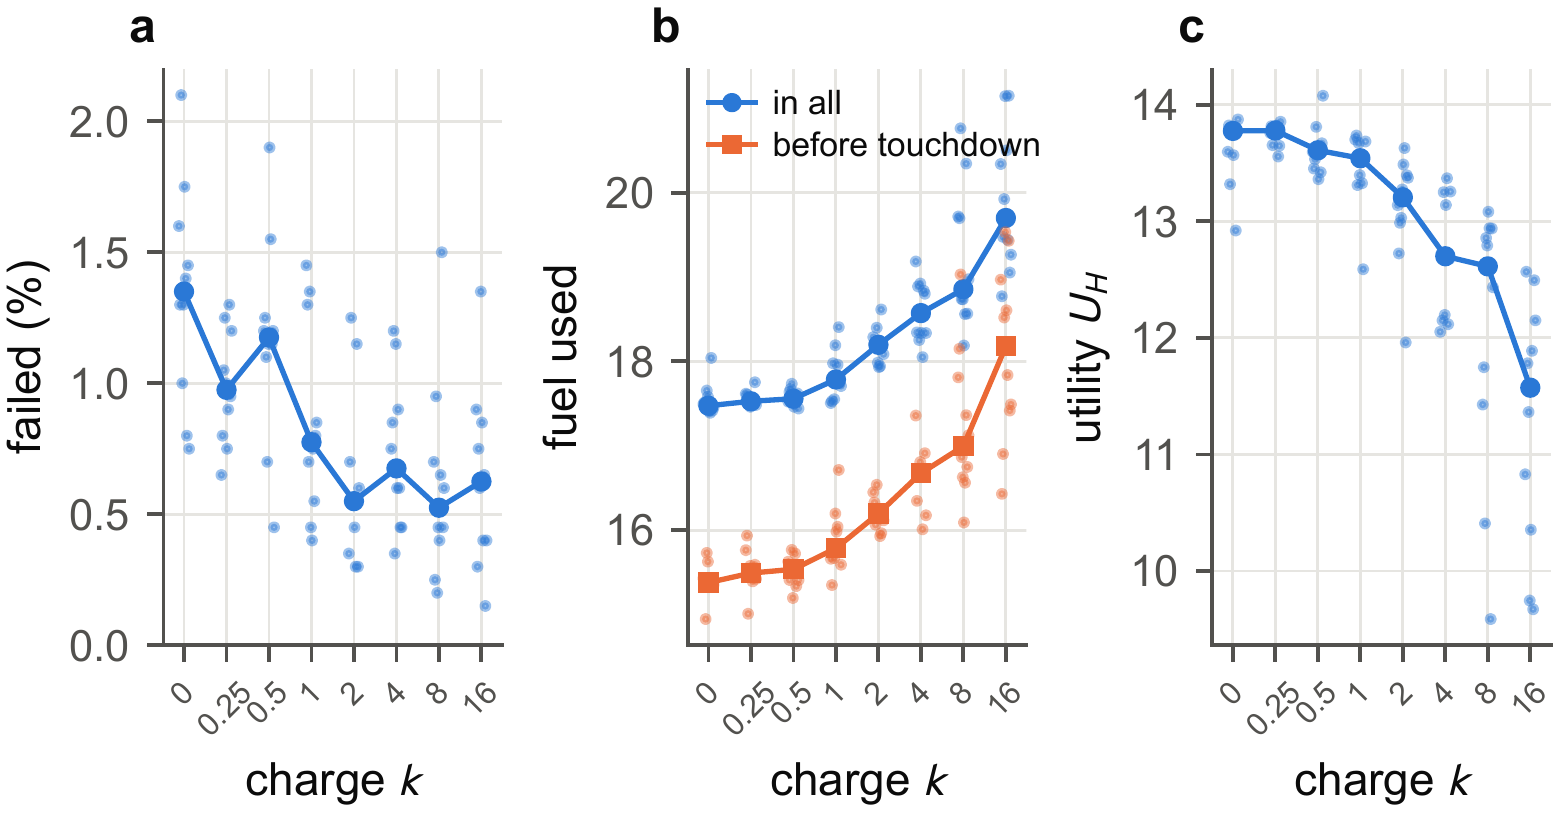

In [2]:
display(Image(filename="figures/landing-flights.png", width=780))
display(Image(filename="figures/landing-summary.png", width=780))

The higher-charge policies descended more slowly and spent more fuel before contact in this comparison. Failure frequencies changed little beyond the first few charges, while stopped utility fell at the largest charges. The frequency estimates and the priced risks are separate quantities. The trace figure shows that at the largest charges fuel use was still rising before the decay phase.

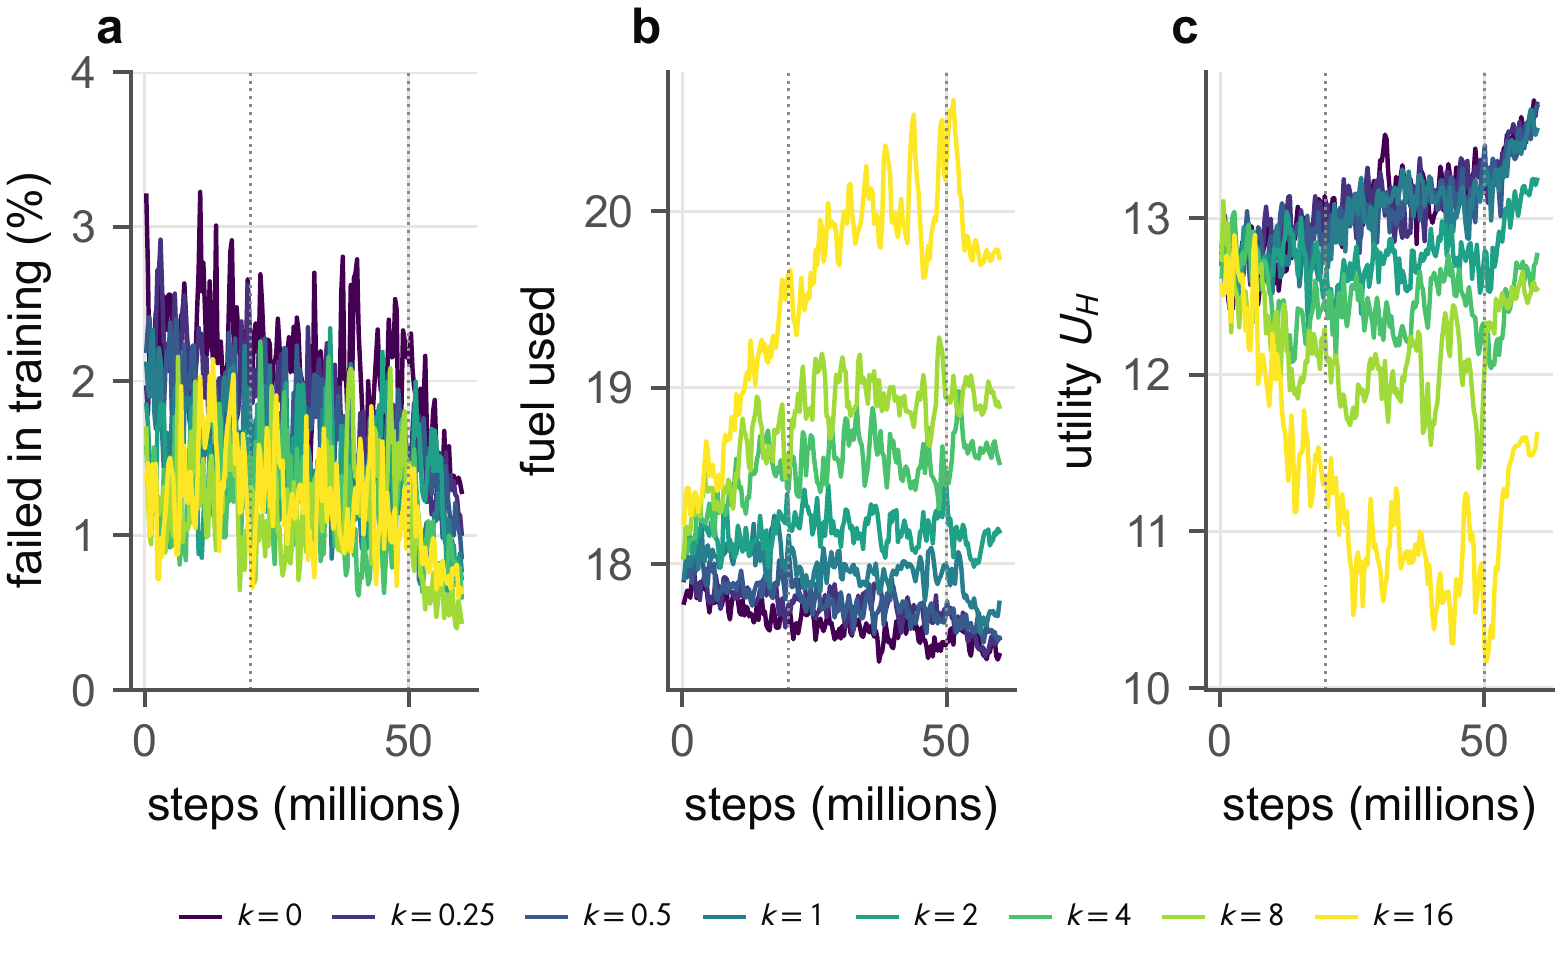

In [3]:
display(Image(filename="figures/landing-convergence.png", width=780))

## Recompute reported quantities and test a tolerance

The failure rate, priced risk and utility columns average the recorded runs across equally weighted seeds. For a validation illustration, take a 2% tolerance through frame 999 and allocate the total error across the 80 fitted policies. Each binomial test uses the stored failure count. The last column evaluates the own-charge shortfall by scoring every tested policy at that charge. The best score in this finite set gives a comparison with the fitted policy. The optimum over all policies is unknown.

In [4]:
campaign = json.loads(Path("data/landing-campaign.json").read_text())
assert (landing.revenue, spec.beta, spec.horizon) == (campaign["revenue"], campaign["beta"], campaign["horizon"])
charges = campaign["worth"]
req = Requirement(T=999, alpha=0.02, zeta=0.05, family=len(charges) * len(campaign["seeds"]))
U = np.array([np.mean([run["U"] for run in campaign["runs"][f"{k:g}"]]) for k in charges])
q = np.array([np.mean([run["q"] for run in campaign["runs"][f"{k:g}"]]) for k in charges])
m = np.array([landing.price(k) for k in charges])
assert np.allclose(m, [campaign["price"][f"{k:g}"] for k in charges])
values = U[:, None] - q[:, None] * m[None, :] / (1 - spec.beta)
shortfalls = values.max(axis=0) - values.diagonal()
assert np.allclose(values, campaign["values"]["matrix"])
assert np.allclose(shortfalls, campaign["values"]["shortfall_at_own_price"])
print(f"{'charge k':>8s} {'failure rate':>14s} {'priced risk':>13s} {'utility':>10s} {'validated':>10s} {'shortfall':>10s}")
for i, k in enumerate(charges):
    key = f"{k:g}"
    seed_runs = campaign["runs"][key]
    failure_rate = np.mean([run["failures"] / run["n"] for run in seed_runs])
    assert np.isclose(failure_rate, campaign["design"][key]["failed_mean"])
    passes = sum(validate_direct(run["failures"], run["n"], req.alpha, req.zeta, req.family).passed for run in seed_runs)
    print(f"{k:8g} {failure_rate:14.2%} {q[i]:13.4f} {U[i]:10.2f} {passes:7d}/{len(seed_runs):<2d} {shortfalls[i]:10.2f}")

charge k   failure rate   priced risk    utility  validated  shortfall


       0          1.34%        0.0071      13.62       3/10       0.12
    0.25          0.98%        0.0051      13.75       6/10       0.00
     0.5          1.16%        0.0061      13.62       2/10       0.16
       1          0.86%        0.0045      13.45       7/10       0.26
       2          0.62%        0.0031      13.10       8/10       0.42
       4          0.73%        0.0038      12.69       8/10       0.75
       8          0.61%        0.0031      12.02       9/10       1.05
      16          0.64%        0.0031      11.28       9/10       1.78


## Fine-tune a candidate and validate its deployed action rule

The example function takes an unpriced checkpoint from the same simulator and trains at the specified charge under PPO. The policy update uses repeated minibatches of a rollout with a clipped actor objective. The function allows a constant-rate or a decaying-rate training phase. The replication scripts preserve the exact environments, schedules and checkpoint handling of the campaign.

In [5]:
def fine_tune(checkpoint, charge, seed, steps, learning_rate):
    from stable_baselines3 import PPO
    from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

    stage = landing.stage(charge)
    venv = DummyVecEnv([lambda: make_env(stage, aid=True) for _ in range(16)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, gamma=spec.beta, clip_reward=1e9)
    monitor = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon)
    try:
        actor = PPO.load(checkpoint, env=venv, device="cpu", seed=seed,
                         custom_objects={"learning_rate": learning_rate})
        actor.learn(steps, callback=monitor, reset_num_timesteps=True)
    finally:
        venv.close()
    return actor, monitor


def validate_flight(actor, charge, seed, n=2_000, alpha=0.02, deterministic=False):
    stage = landing.stage(charge)
    episodes = evaluate(lambda: make_env(stage), sb3_policy(actor, deterministic=deterministic), n,
                        spec=spec, stage=stage, T=spec.horizon - 1, seed=seed)
    return episodes.validate(alpha, zeta=0.05, family=1)

Validate the stochastic actor or its mean-action version according to how it will be deployed. The helper covers a single fixed actor. The [replication script](https://github.com/pma-papers/bpg-replication/blob/174651d8ffe7ba5a521fb06e109d8387e58c0cf9/fuel-tank/lunar_landing_paper.py) documents all three training designs and the inputs to the manuscript figures.